# Diagnose the major-seventh failure without retraining

Both saved models have zero exact maj7 accuracy on the held-out test split. This notebook investigates support, assigned weights, substitute predictions, ranking/probability, musical cues and input simplification **before changing any model**.

Notebooks 06/07, their output directories, both checkpoints, model/preprocessing source and all dataset artifacts are read-only inputs. Only a fresh `outputs/maj7_failure_analysis/` run is written. There is no optimizer, backpropagation or training loop here. Counts and metrics use `target_loss_mask & beat_attention_mask` and exclude reserved targets; supervised N remains part of the binary-quality negative set.

Exact top-k means the complete target label (root, extension and inversion) occurs in the top k. Aggregated maj7 precision/recall/F1 instead evaluates binary **quality detection**, ignoring root/inversion. These are reported separately.

## 1. Read the existing notebooks and saved configurations

In [1]:
from pathlib import Path
import sys, json, csv, hashlib, time
from collections import Counter, defaultdict
from dataclasses import asdict
from datetime import datetime, timedelta, timezone
import numpy as np
import torch
import matplotlib.pyplot as plt
import nbformat
from IPython.display import HTML, display
from html import escape
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'experiments/rahul/src').is_dir())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset,make_dataloader
from experiments.rahul.src.model.checkpoint import load_checkpoint
from experiments.rahul.src.weighted_training import supervised_mask,sqrt_inverse_weights
from experiments.rahul.src.maj7_diagnostics import chord_parts,binary_quality_metrics,diagnose_logits,melody_features
from experiments.rahul.src.canonicalize_chords import ROOT_TO_PITCH_CLASS
from experiments.rahul.src.build_synthetic_dataset import simplify,context
BASELINE_RUN=root/'experiments/rahul/outputs/transformer_training/notebook_full_inputs_20261019_194104_127905'
WEIGHTED_RUN=root/'experiments/rahul/outputs/weighted_transformer/weighted_20261020_003318_832489'
BASELINE_NOTEBOOK=root/'experiments/rahul/notebooks/06_train_transformer.ipynb'
WEIGHTED_NOTEBOOK=root/'experiments/rahul/notebooks/07_train_transformer_weighted.ipynb'
for source in (BASELINE_NOTEBOOK,WEIGHTED_NOTEBOOK):
    existing=nbformat.read(source,as_version=4)
    print(source.name,'code cells:',sum(cell.cell_type=='code' for cell in existing.cells))
baseline_config=json.loads((BASELINE_RUN/'training_config.json').read_text())
weighted_config=json.loads((WEIGHTED_RUN/'experiment_config.json').read_text())
assert baseline_config['model']==weighted_config['model']
assert baseline_config['input_columns']==weighted_config['input_columns']
assert baseline_config['target_columns']==weighted_config['target_columns']
DATASET_DIR=Path(baseline_config['dataset'])
if not DATASET_DIR.is_dir(): DATASET_DIR=root/'experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar'
INPUT_KEYS=tuple(x.removeprefix('inputs__') for x in baseline_config['input_columns'])
DEVICE=torch.device('cpu'); torch.set_num_threads(4)
features=json.loads((DATASET_DIR/'feature_vocabularies.json').read_text())
labels=json.loads((DATASET_DIR/'target_vocabulary.json').read_text())['id_to_token']
parts=[chord_parts(label) for label in labels]
maj7_ids=[i for i,(_,quality) in enumerate(parts) if quality=='maj7']
reserved_ids=tuple(i for i,label in enumerate(labels) if label in ('PAD','UNK'))
stamp=datetime.now(timezone(timedelta(hours=5,minutes=30))).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR=root/'experiments/rahul/outputs/maj7_failure_analysis'/('diagnostic_'+stamp)
RUN_DIR.mkdir(parents=True,exist_ok=False)
print('Maj7 classes in saved vocabulary:',len(maj7_ids),'Output:',RUN_DIR)

Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\srjay\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


06_train_transformer.ipynb code cells: 17
07_train_transformer_weighted.ipynb code cells: 15
Maj7 classes in saved vocabulary: 24 Output: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\maj7_failure_analysis\diagnostic_20261020_130052_279767


In [2]:
def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''): h.update(chunk)
    return h.hexdigest()
def save_json(name,value):
    (RUN_DIR/name).write_text(json.dumps(value,indent=2,allow_nan=False)+'\n',encoding='utf-8')
def table(rows,percentage_keys=()):
    if not rows: return HTML('<p>No supported examples.</p>')
    headers=list(rows[0]); body=[]
    for row in rows:
        vals=['N/A' if row[k] is None else (f'{100*row[k]:.2f}%' if k in percentage_keys else str(row[k])) for k in headers]
        body.append('<tr>'+''.join('<td style="padding:5px 9px">'+escape(x)+'</td>' for x in vals)+'</tr>')
    return HTML('<div style="max-height:550px;overflow:auto"><table><tr>'+''.join('<th style="padding:7px">'+escape(k)+'</th>' for k in headers)+'</tr>'+''.join(body)+'</table></div>')
protected=[BASELINE_NOTEBOOK,WEIGHTED_NOTEBOOK,BASELINE_RUN/'best.pt',WEIGHTED_RUN/'best_weighted.pt']
protected+=sorted(BASELINE_RUN.glob('*'))+sorted(WEIGHTED_RUN.glob('*'))
protected+=[DATASET_DIR/'feature_vocabularies.json',DATASET_DIR/'target_vocabulary.json']
protected+=sorted((root/'experiments/rahul/src/model').glob('*.py'))
protected+=[root/'experiments/rahul/src/transformer_dataset.py',root/'experiments/rahul/src/encode_features.py']
protected_hashes={str(p):sha(p) for p in protected if p.is_file()}
save_json('analysis_config.json',{'baseline':str(BASELINE_RUN),'weighted':str(WEIGHTED_RUN),
    'dataset':str(DATASET_DIR),'input_keys':INPUT_KEYS,'device':str(DEVICE),
    'protected_hashes':protected_hashes,'training':False})
loaders={split:make_dataloader(SavedSequenceDataset(DATASET_DIR/f'{split}_sequences.json'),batch_size=32,shuffle=False)
         for split in ('train','validation','test')}
print('Protected files:',len(protected_hashes))

Protected files: 61


## 2. Count every maj7 target class in all splits and inspect major-triad priors

Counts are supervised real beats, not all unmasked source-reference intervals. Saved targets at excluded positions are -100 and cannot be assigned to a quality. Distinct track counts show whether large beat support is concentrated in few tracks.

For musical-cue analysis, relative pitch class 11 means a melody pitch one semitone below the reference root octave. It is only a possible maj7 cue: it can also be a non-chord tone. Its absence in a melody does not prove absence of maj7 harmony. Categorical-context overlap does not imply that full melody/timing tensors are identical.

In [3]:
split_counts={}; class_tracks={}; cue_rows=[]
training_basic_priors=defaultdict(Counter)
training_context_groups=defaultdict(Counter)
quality_list=[quality for _,quality in parts]
root_pc_lookup=torch.tensor([ROOT_TO_PITCH_CLASS.get(r,-1) for r,_ in parts])
major_lookup=torch.tensor([q=='maj' for q in quality_list])
maj7_lookup=torch.tensor([q=='maj7' for q in quality_list])
cue_accumulators={}
for split,loader in loaders.items():
    counts=torch.zeros(len(labels),dtype=torch.int64)
    tracks=defaultdict(set)
    cue_counts=torch.zeros(24,dtype=torch.int64)
    cue_hits=torch.zeros(24,dtype=torch.int64)
    silent_counts=torch.zeros(24,dtype=torch.int64)
    note_totals=torch.zeros(24,dtype=torch.float64)
    for batch in loader:
        inputs,targets=batch['inputs'],batch['targets']
        valid=supervised_mask(targets,inputs['beat_attention_mask'],len(labels),reserved_ids)
        ids=targets['target_chord_ids']
        safe_ids=ids.clamp_min(0)
        counts+=torch.bincount(ids[valid],minlength=len(labels))
        is_maj7=valid & maj7_lookup[safe_ids]
        for b,t in is_maj7.nonzero().tolist():
            tracks[int(ids[b,t])].add(batch['metadata'][b]['track_id'])
        selected=valid & (major_lookup[safe_ids] | maj7_lookup[safe_ids])
        pcs=root_pc_lookup[safe_ids]
        group=maj7_lookup[safe_ids].long()*12+pcs
        note_mask=inputs['melody_note_mask'] & (inputs['melody_pitch_ids']>=2)
        relative=(inputs['melody_pitch_ids']-2-pcs.unsqueeze(-1))%12
        cue=((relative==11)&note_mask).any(-1)
        cue_counts+=torch.bincount(group[selected],minlength=24)
        cue_hits+=torch.bincount(group[selected & cue],minlength=24)
        silent_counts+=torch.bincount(group[selected & inputs['melody_silent']],minlength=24)
        note_totals+=torch.bincount(group[selected],weights=note_mask.sum(-1)[selected].double(),minlength=24)
        if split=='train':
            values={key:inputs[key].tolist() for key in ('basic_chord_ids','key_ids','mode_ids','roman_ids','harmonic_function_ids')}
            genres=[tuple(torch.nonzero(v).flatten().tolist()) for v in inputs['genre_features']]
            id_lists=ids.tolist()
            for b,t in valid.nonzero().tolist():
                basic=values['basic_chord_ids'][b][t]
                quality=quality_list[id_lists[b][t]] or labels[id_lists[b][t]]
                training_basic_priors[basic][quality]+=1
                if quality in ('maj','maj7'):
                    key=tuple(values[name][b][t] for name in values)+(genres[b],)
                    training_context_groups[key][quality]+=1
    split_counts[split]=counts
    class_tracks[split]=tracks
    cue_accumulators[split]=(cue_counts,cue_hits,silent_counts,note_totals)
    print(split,'valid targets:',int(counts.sum()),'maj7 targets:',int(counts[maj7_ids].sum()))
    for qid,quality in enumerate(('maj','maj7')):
        for root_name,root_pc in ROOT_TO_PITCH_CLASS.items():
            # Canonical sharp spellings only, to avoid duplicating enharmonic roots.
            if 'b' in root_name: continue
            index=qid*12+root_pc; support=int(cue_counts[index])
            if support:
                cue_rows.append({'split':split,'quality':quality,'root':root_name,'support':support,
                    'with_major_seventh_melody_pc':int(cue_hits[index]),
                    'cue_fraction':int(cue_hits[index])/support,'silent':int(silent_counts[index]),
                    'mean_notes':float(note_totals[index])/support})
count_rows=[{'target_id':i,'maj7_label':labels[i],
    **{split+'_count':int(split_counts[split][i]) for split in loaders},
    **{split+'_tracks':len(class_tracks[split][i]) for split in loaders}} for i in maj7_ids]
save_json('maj7_split_counts.json',count_rows)
save_json('melody_cue_by_split_root_quality.json',cue_rows)
display(table(count_rows))

train valid targets: 184867 maj7 targets: 3284


validation valid targets: 11214 maj7 targets: 95


test valid targets: 14077 maj7 targets: 926


target_id,maj7_label,train_count,validation_count,test_count,train_tracks,validation_tracks,test_tracks
22,A#:maj7,286,0,26,13,0,1
23,A#:maj7/2,3,0,0,1,0,0
24,A#:maj7/4,12,0,0,1,0,0
54,A:maj7,59,0,150,5,0,2
55,A:maj7/5,22,0,0,1,0,0
56,A:maj7/7,2,0,0,1,0,0
88,B:maj7,106,17,0,6,1,0
89,B:maj7/3,4,6,0,2,1,0
119,C#:maj7,467,0,69,10,0,1
120,C#:maj7/5,3,0,0,1,0,0


## 3. Assigned weights for every major-seventh label

Read the actual class-weight CSV from the weighted run, then recompute the formula from freshly scanned valid training counts. No new weights are used to train anything. Compare each maj7 weight with its same-root plain major-triad weight.

In [4]:
with (WEIGHTED_RUN/'class_weights.csv').open(newline='',encoding='utf-8') as stream:
    saved_weights={int(row['target_id']):row for row in csv.DictReader(stream)}
recomputed=sqrt_inverse_weights(split_counts['train'],alpha=weighted_config['alpha'],maximum=weighted_config['maximum_weight'])
for i in range(len(labels)):
    assert int(saved_weights[i]['training_count'])==int(split_counts['train'][i])
    assert abs(float(saved_weights[i]['class_weight'])-float(recomputed[i]))<1e-6
weight_rows=[]
for i in maj7_ids:
    root_name,_=parts[i]; triad=f'{root_name}:maj'
    j=labels.index(triad) if triad in labels else None
    weight_rows.append({'maj7_label':labels[i],'train_count':int(split_counts['train'][i]),
        'assigned_weight':float(recomputed[i]),'plain_triad':triad,
        'triad_train_count':int(split_counts['train'][j]) if j is not None else None,
        'triad_weight':float(recomputed[j]) if j is not None else None,
        'weight_ratio_maj7_to_triad':float(recomputed[i]/recomputed[j]) if j is not None and recomputed[j]>0 else None})
save_json('maj7_assigned_weights.json',weight_rows)
display(table(weight_rows))

maj7_label,train_count,assigned_weight,plain_triad,triad_train_count,triad_weight,weight_ratio_maj7_to_triad
A#:maj7,286,1.2712081670761108,A#:maj,3322,0.37299230694770813,3.408135175704956
A#:maj7/2,3,5.0,A#:maj,3322,0.37299230694770813,13.405101776123047
A#:maj7/4,12,5.0,A#:maj,3322,0.37299230694770813,13.405101776123047
A:maj7,59,2.798811912536621,A:maj,7874,0.2422713190317154,11.552386283874512
A:maj7/5,22,4.583406448364258,A:maj,7874,0.2422713190317154,18.918485641479492
A:maj7/7,2,5.0,A:maj,7874,0.2422713190317154,20.638019561767578
B:maj7,106,2.088078260421753,B:maj,5467,0.29075363278388977,7.181606769561768
B:maj7/3,4,5.0,B:maj,5467,0.29075363278388977,17.19668960571289
C#:maj7,467,0.994812548160553,C#:maj,4607,0.3167310059070587,3.1408751010894775
C#:maj7/5,3,5.0,C#:maj,4607,0.3167310059070587,15.786266326904297


## 4. Read-only test inference, exact ranks, probability and quality confusion

Both models use their saved best checkpoints. Probabilities are ordinary softmax over the complete saved output vocabulary, without filtering reserved logits or renormalizing musical candidates. Exact ties use vocabulary order. Rank 1/?3/?5 defines exact top-1/3/5 success.

We define probability thresholds 0.10 and 0.20 before inspecting results to quantify what ?substantial? could mean. These scores are not assumed calibrated. Binary maj7-quality true/false positives are calculated over **all valid test beats**, not just reference maj7 beats.

In [5]:
models={'baseline':load_checkpoint(BASELINE_RUN/'best.pt',DATASET_DIR,DEVICE),
        'weighted':load_checkpoint(WEIGHTED_RUN/'best_weighted.pt',DATASET_DIR,DEVICE)}
assert asdict(models['baseline'].config)==asdict(models['weighted'].config)==baseline_config['model']
quality_confusion={name:Counter() for name in models}
full_correct=Counter(); full_support=0
records=[]
field_vocab={'basic_chord_ids':'basic_chord_canonical','key_ids':'key','mode_ids':'mode',
             'roman_ids':'roman_numeral','harmonic_function_ids':'harmonic_function'}
for batch in loaders['test']:
    inputs={key:batch['inputs'][key].to(DEVICE) for key in INPUT_KEYS}
    targets=batch['targets']
    valid=supervised_mask(targets,inputs['beat_attention_mask'],len(labels),reserved_ids)
    ids=targets['target_chord_ids']
    positions=(valid & maj7_lookup[ids.clamp_min(0)]).nonzero().tolist()
    output={}
    with torch.no_grad():
        for name,model in models.items():
            logits=model(inputs).cpu()
            assert torch.isfinite(logits).all()
            prediction=logits.argmax(-1)
            truth_quality=maj7_lookup[ids.clamp_min(0)]
            predicted_quality=maj7_lookup[prediction]
            quality_confusion[name]['tp']+=int((valid & truth_quality & predicted_quality).sum())
            quality_confusion[name]['fp']+=int((valid & ~truth_quality & predicted_quality).sum())
            quality_confusion[name]['fn']+=int((valid & truth_quality & ~predicted_quality).sum())
            full_correct[name]+=int((prediction[valid]==ids[valid]).sum())
            output[name]=logits
    full_support+=int(valid.sum())
    for b,t in positions:
        target_id=int(ids[b,t]); root_name,_=parts[target_id]
        decoded={field:features['vocabs'][vocab]['id_to_token'][int(inputs[field][b,t])]
                 for field,vocab in field_vocab.items()}
        genre=[features['genres'][i] for i in torch.nonzero(inputs['genre_features'][b]).flatten().tolist()]
        note=melody_features(inputs,b,t,ROOT_TO_PITCH_CLASS[root_name])
        record={'track_id':batch['metadata'][b]['track_id'],
            'sequence_index':int(batch['metadata'][b]['sequence_index']),
            'position_in_sequence':t,'beat_index':int(inputs['beat_index'][b,t]),
            'reference_id':target_id,'reference_chord':labels[target_id],
            'reference_root':root_name,'training_support_for_exact_class':int(split_counts['train'][target_id]),
            'assigned_weight':float(recomputed[target_id]),'categorical_inputs':decoded,
            'genre_tags':genre,'beat_position':float(inputs['beat_position'][b,t]),
            'bar_number':float(inputs['bar_number'][b,t]),'relative_bar_number':float(inputs['relative_bar_number'][b,t]),
            'event_duration':float(inputs['event_duration'][b,t]),
            'sequence_basic_chords':[features['vocabs']['basic_chord_canonical']['id_to_token'][int(value)]
                for value in inputs['basic_chord_ids'][b][inputs['beat_attention_mask'][b]]],
            'melody':note,'predictions':{name:diagnose_logits(logits[b,t],target_id,labels) for name,logits in output.items()}}
        records.append(record)
assert len(records)==int(split_counts['test'][maj7_ids].sum())
assert full_support==int(split_counts['test'].sum())
assert full_correct['baseline']==json.loads((BASELINE_RUN/'results.json').read_text())['test']['correct_targets']
assert full_correct['weighted']==json.loads((WEIGHTED_RUN/'results.json').read_text())['weighted']['exact_correct']
save_json('maj7_example_predictions.json',records)
print('Maj7 reference examples analyzed:',len(records),'across',len({r['track_id'] for r in records}),'test tracks')

Maj7 reference examples analyzed: 926 across 12 test tracks


## 5. Major-seventh top-k accuracy, binary quality precision/recall/F1 and probability summaries

model,reference_maj7_beats,exact_top1_correct,exact_top1_accuracy,exact_top3_correct,exact_top3_accuracy,exact_top5_correct,exact_top5_accuracy,reference_probability_mean,reference_probability_median,reference_probability_p10,reference_probability_p90,reference_probability_at_least_0_10,reference_probability_at_least_0_20,reference_rank_median,winner_probability_mean,plain_major_triad_probability_mean,all_maj7_probability_mass_mean,same_root_maj7_probability_mass_mean,same_root_plain_triad_predictions,same_root_major_any_inversion_predictions
baseline,926,0,0.00%,489,52.81%,926,100.00%,0.03599612479984205,0.015347789973020554,0.004307931521907449,0.10607237368822098,101,26,3.0,0.863325860375462,0.863325860375462,0.04308258295868831,0.041295258440962365,926,926
weighted,926,0,0.00%,457,49.35%,759,81.97%,0.047750456496011104,0.022618383169174194,0.009301314130425453,0.12417428195476532,124,49,4.0,0.7032219826949853,0.703217093054342,0.056163234010612344,0.05378178967370151,925,926


model,true_positive,false_positive,false_negative,precision,recall,f1,definition
baseline,0,3,926,0.00%,0.00%,0.00%,"Binary maj7-quality detection across all valid beats, ignoring root and inversion."
weighted,0,4,926,0.00%,0.00%,0.00%,"Binary maj7-quality detection across all valid beats, ignoring root and inversion."


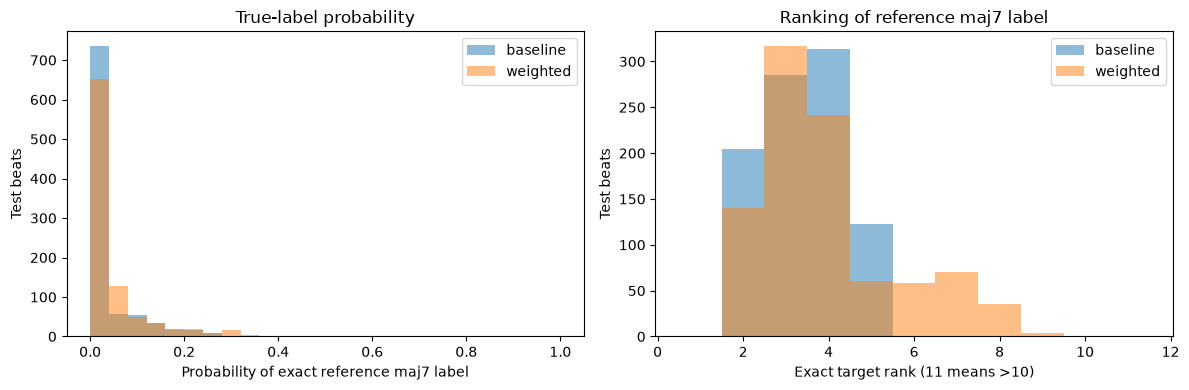

In [6]:
summaries={}
for name in models:
    rows=[r['predictions'][name] for r in records]
    ranks=np.asarray([r['exact_rank'] for r in rows]); probabilities=np.asarray([r['reference_probability'] for r in rows])
    confusion=quality_confusion[name]
    summaries[name]={'reference_maj7_beats':len(rows),
        'exact_top1_correct':int((ranks<=1).sum()),'exact_top1_accuracy':float((ranks<=1).mean()),
        'exact_top3_correct':int((ranks<=3).sum()),'exact_top3_accuracy':float((ranks<=3).mean()),
        'exact_top5_correct':int((ranks<=5).sum()),'exact_top5_accuracy':float((ranks<=5).mean()),
        'maj7_quality_detection':binary_quality_metrics(confusion['tp'],confusion['fp'],confusion['fn']),
        'reference_probability_mean':float(probabilities.mean()),'reference_probability_median':float(np.median(probabilities)),
        'reference_probability_p10':float(np.quantile(probabilities,.1)),'reference_probability_p90':float(np.quantile(probabilities,.9)),
        'reference_probability_at_least_0_10':int((probabilities>=.1).sum()),
        'reference_probability_at_least_0_20':int((probabilities>=.2).sum()),
        'reference_rank_median':float(np.median(ranks)),
        'winner_probability_mean':float(np.mean([r['winner_probability'] for r in rows])),
        'plain_major_triad_probability_mean':float(np.mean([r['plain_major_triad_probability'] for r in rows])),
        'all_maj7_probability_mass_mean':float(np.mean([r['all_maj7_probability_mass'] for r in rows])),
        'same_root_maj7_probability_mass_mean':float(np.mean([r['same_root_maj7_probability_mass'] for r in rows])),
        'same_root_plain_triad_predictions':sum(r['predicted_corresponding_plain_triad'] for r in rows),
        'same_root_major_any_inversion_predictions':sum(r['predicted_same_root_major_any_inversion'] for r in rows)}
save_json('maj7_metrics_and_probability.json',summaries)
display(table([{'model':name,**{k:v for k,v in s.items() if k not in ('maj7_quality_detection',)}} for name,s in summaries.items()],
              ('exact_top1_accuracy','exact_top3_accuracy','exact_top5_accuracy')))
display(table([{'model':name,**s['maj7_quality_detection']} for name,s in summaries.items()],('precision','recall','f1')))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name in models:
    axes[0].hist([r['predictions'][name]['reference_probability'] for r in records],bins=np.linspace(0,1,26),alpha=.5,label=name)
    axes[1].hist([min(r['predictions'][name]['exact_rank'],11) for r in records],bins=np.arange(.5,12.5,1),alpha=.5,label=name)
axes[0].set(xlabel='Probability of exact reference maj7 label',ylabel='Test beats',title='True-label probability')
axes[1].set(xlabel='Exact target rank (11 means >10)',ylabel='Test beats',title='Ranking of reference maj7 label')
for ax in axes: ax.legend()
fig.tight_layout(); fig.savefig(RUN_DIR/'maj7_probability_and_rank.png',dpi=160); plt.show()

## 6. Which labels replace maj7? Focus confusion tables

The focus labels are exact G:maj7, A:maj7, G#:maj7 and C#:maj7. Tables also retain all other observed maj7 classes. A same-root major prediction counts as an exact error; the plain triad and any-major-inversion definitions are reported separately above.

In [7]:
focus_labels=['G:maj7','A:maj7','G#:maj7','C#:maj7']
confusion_rows=[]
for reference in dict.fromkeys(focus_labels+[labels[i] for i in maj7_ids]):
    matching=[r for r in records if r['reference_chord']==reference]
    for name in models:
        counter=Counter(r['predictions'][name]['predicted_label'] for r in matching)
        if not matching:
            confusion_rows.append({'model':name,'reference':reference,'test_support':0,'predicted':'N/A','count':0,'fraction':None})
        else:
            for prediction,count in counter.most_common():
                confusion_rows.append({'model':name,'reference':reference,'test_support':len(matching),
                                       'predicted':prediction,'count':count,'fraction':count/len(matching)})
save_json('maj7_confusion_tables.json',confusion_rows)
for reference in focus_labels:
    print(reference)
    display(table([r for r in confusion_rows if r['reference']==reference],('fraction',)))
print('All reference maj7 labels and their replacement predictions:')
display(table([r for r in confusion_rows if r['test_support']>0],('fraction',)))

G:maj7


model,reference,test_support,predicted,count,fraction
baseline,G:maj7,532,G:maj,532,100.00%
weighted,G:maj7,532,G:maj,532,100.00%


A:maj7


model,reference,test_support,predicted,count,fraction
baseline,A:maj7,150,A:maj,150,100.00%
weighted,A:maj7,150,A:maj,149,99.33%
weighted,A:maj7,150,A:maj/7,1,0.67%


G#:maj7


model,reference,test_support,predicted,count,fraction
baseline,G#:maj7,106,G#:maj,106,100.00%
weighted,G#:maj7,106,G#:maj,106,100.00%


C#:maj7


model,reference,test_support,predicted,count,fraction
baseline,C#:maj7,69,C#:maj,69,100.00%
weighted,C#:maj7,69,C#:maj,69,100.00%


All reference maj7 labels and their replacement predictions:


model,reference,test_support,predicted,count,fraction
baseline,G:maj7,532,G:maj,532,100.00%
weighted,G:maj7,532,G:maj,532,100.00%
baseline,A:maj7,150,A:maj,150,100.00%
weighted,A:maj7,150,A:maj,149,99.33%
weighted,A:maj7,150,A:maj/7,1,0.67%
baseline,G#:maj7,106,G#:maj,106,100.00%
weighted,G#:maj7,106,G#:maj,106,100.00%
baseline,C#:maj7,69,C#:maj,69,100.00%
weighted,C#:maj7,69,C#:maj,69,100.00%
baseline,A#:maj7,26,A#:maj,26,100.00%


## 7. Does the basic input retain a seventh distinction?

Inspect the original simplification and context functions directly, without generating new events. Also count empirical training targets conditioned on each basic chord. The categorical-context comparison uses only basic chord, key, mode, Roman/function and genre; it does not claim note/timing features or complete sequences are identical.

In [8]:
basic_vocab=features['vocabs']['basic_chord_canonical']['id_to_token']
simplification_rows=[]; prior_rows=[]
for root_name in sorted({parts[i][0] for i in maj7_ids}):
    triad=simplify(root_name+':maj'); seventh=simplify(root_name+':maj7')
    same_basic=all(triad[k]==seventh[k] for k in ('basic_chord','basic_root','basic_quality'))
    same_context=all(context(triad,key,mode)==context(seventh,key,mode)
        for key in ROOT_TO_PITCH_CLASS for mode in ('major','minor'))
    simplification_rows.append({'reference_pair':root_name+':maj versus '+root_name+':maj7',
        'triad_basic':triad['basic_chord'],'seventh_basic':seventh['basic_chord'],
        'same_basic_root_quality':same_basic,'same_roman_function_given_same_key_mode':same_context})
for basic_id,counts in training_basic_priors.items():
    if counts['maj7']:
        total=sum(counts.values())
        prior_rows.append({'basic_input':basic_vocab[basic_id],'all_valid_train_targets':total,
            'maj_training_targets':counts['maj'],'maj7_training_targets':counts['maj7'],
            'maj7_fraction_given_basic':counts['maj7']/total})
prior_rows.sort(key=lambda r:-r['maj7_training_targets'])
mixed=[counts for counts in training_context_groups.values() if counts['maj'] and counts['maj7']]
input_findings={'all_roots_basic_distinction_removed':all(r['same_basic_root_quality'] for r in simplification_rows),
    'same_key_mode_context_does_not_restore_extension':all(r['same_roman_function_given_same_key_mode'] for r in simplification_rows),
    'training_categorical_groups_containing_both_maj_and_maj7':len(mixed),
    'maj7_beats_in_mixed_categorical_groups':sum(r['maj7'] for r in mixed),
    'maj_beats_in_mixed_categorical_groups':sum(r['maj'] for r in mixed),
    'qualification':'Categorical collisions do not imply identical melody, timing, genre-independent sequence or all model inputs.'}
save_json('basic_input_simplification.json',{'rules':simplification_rows,'train_priors':prior_rows,'findings':input_findings})
display(table(simplification_rows)); display(table(prior_rows,('maj7_fraction_given_basic',)))
display(input_findings)

reference_pair,triad_basic,seventh_basic,same_basic_root_quality,same_roman_function_given_same_key_mode
A:maj versus A:maj7,A,A,True,True
A#:maj versus A#:maj7,A#,A#,True,True
B:maj versus B:maj7,B,B,True,True
C:maj versus C:maj7,C,C,True,True
C#:maj versus C#:maj7,C#,C#,True,True
D:maj versus D:maj7,D,D,True,True
D#:maj versus D#:maj7,D#,D#,True,True
E:maj versus E:maj7,E,E,True,True
F:maj versus F:maj7,F,F,True,True
F#:maj versus F#:maj7,F#,F#,True,True


basic_input,all_valid_train_targets,maj_training_targets,maj7_training_targets,maj7_fraction_given_basic
C,10890,10261,629,5.78%
F,7872,7318,554,7.04%
G,12223,11742,481,3.94%
C#,5193,4723,470,9.05%
A#,3992,3691,301,7.54%
F#,3791,3538,253,6.67%
D,10379,10211,168,1.62%
B,5734,5624,110,1.92%
D#,3381,3286,95,2.81%
A,8402,8319,83,0.99%


{'all_roots_basic_distinction_removed': True,
 'same_key_mode_context_does_not_restore_extension': True,
 'training_categorical_groups_containing_both_maj_and_maj7': 96,
 'maj7_beats_in_mixed_categorical_groups': 2443,
 'maj_beats_in_mixed_categorical_groups': 5823,
 'qualification': 'Categorical collisions do not imply identical melody, timing, genre-independent sequence or all model inputs.'}

## 8. Musical cues and representative examples

Compare the presence of a root-relative major seventh in the melody for actual maj7 versus maj references. Root-stratified counts are saved to avoid hiding different root distributions. This is descriptive, not a causal test.

Representative examples are chosen deterministically per requested root: highest baseline reference probability, best weighted rank and first available example with a major-seventh pitch-class cue. Duplicates are removed. Full active melody pitch/timing, key/mode, Roman/function, genre, source beat location and sequence basic progression are retained in the JSON.

In [9]:
cue_summary=[]
for split in loaders:
    counts,hits,silent,notes=cue_accumulators[split]
    for qid,quality in enumerate(('maj','maj7')):
        sl=slice(qid*12,(qid+1)*12); support=int(counts[sl].sum())
        cue_summary.append({'split':split,'reference_quality':quality,'support':support,
            'major_seventh_pc_in_beat':int(hits[sl].sum()),
            'cue_fraction':int(hits[sl].sum())/support if support else None,
            'silent_fraction':int(silent[sl].sum())/support if support else None,
            'mean_notes_per_beat':float(notes[sl].sum())/support if support else None})
sequence_cue_count=sum(r['melody']['major_seventh_pc_in_sequence'] for r in records)
save_json('melody_cue_summary.json',{'by_split_quality':cue_summary,
    'test_maj7_sequence_cue_count':sequence_cue_count,'test_maj7_support':len(records)})
display(table(cue_summary,('cue_fraction','silent_fraction')))
print('Test maj7 beats with a relative-seventh note somewhere in their sequence:',sequence_cue_count,'of',len(records))
representatives=[]; seen=set()
for reference in focus_labels:
    candidates=[r for r in records if r['reference_chord']==reference]
    if not candidates: continue
    choices=[('highest_baseline_true_probability',max(candidates,key=lambda r:r['predictions']['baseline']['reference_probability'])),
             ('best_weighted_exact_rank',min(candidates,key=lambda r:r['predictions']['weighted']['exact_rank']))]
    cue_candidate=next((r for r in candidates if r['melody']['major_seventh_pc_in_beat']),None)
    if cue_candidate is not None: choices.append(('first_with_major_seventh_melody_cue',cue_candidate))
    for reason,record in choices:
        identity=(record['track_id'],record['beat_index'])
        if identity not in seen:
            representatives.append({'selection_reason':reason,**record}); seen.add(identity)
save_json('representative_maj7_examples.json',representatives)
for record in representatives:
    print('Example:',record['track_id'],'beat',record['beat_index'],'reference',record['reference_chord'],'selection:',record['selection_reason'])
    display({'inputs':record['categorical_inputs'],'genre':record['genre_tags'],
        'melody_rounded_midi':record['melody']['rounded_midi'],
        'melody_timing_duration_onset_overlap':record['melody']['melody_timing'],
        'relative_pitch_classes':record['melody']['relative_pitch_classes_to_reference_root'],
        'major_seventh_cue_in_beat':record['melody']['major_seventh_pc_in_beat'],
        'major_seventh_cue_in_sequence':record['melody']['major_seventh_pc_in_sequence'],
        'baseline':record['predictions']['baseline'],'weighted':record['predictions']['weighted']})

split,reference_quality,support,major_seventh_pc_in_beat,cue_fraction,silent_fraction,mean_notes_per_beat
train,maj,79843,7336,9.19%,11.39%,1.8096389163733828
train,maj7,3284,1145,34.87%,9.17%,1.8852009744214373
validation,maj,6046,664,10.98%,9.87%,1.959808137611644
validation,maj7,95,42,44.21%,4.21%,2.0842105263157893
test,maj,5040,525,10.42%,10.75%,2.0660714285714286
test,maj7,926,232,25.05%,13.93%,1.8898488120950323


Test maj7 beats with a relative-seventh note somewhere in their sequence: 633 of 926
Example: 225666 beat 583 reference G:maj7 selection: highest_baseline_true_probability


{'inputs': {'basic_chord_ids': 'G',
  'key_ids': 'B',
  'mode_ids': 'minor',
  'roman_ids': 'VI',
  'harmonic_function_ids': 'unknown'},
 'genre': ['UNK', 'funk', 'house', 'pop', 'soul'],
 'melody_rounded_midi': [78],
 'melody_timing_duration_onset_overlap': [[0.50020831823349,
   -0.4997708201408386,
   0.00043750001350417733]],
 'relative_pitch_classes': [11],
 'major_seventh_cue_in_beat': True,
 'major_seventh_cue_in_sequence': True,
 'baseline': {'predicted_id': 378,
  'predicted_label': 'G:maj',
  'exact_rank': 2,
  'top1_correct': False,
  'top3_correct': True,
  'top5_correct': True,
  'reference_probability': 0.12248612195253372,
  'winner_probability': 0.77414870262146,
  'winner_minus_reference_logit': 1.843766212463379,
  'all_maj7_probability_mass': 0.12436425685882568,
  'same_root_maj7_probability_mass': 0.12248612195253372,
  'plain_major_triad': 'G:maj',
  'plain_major_triad_probability': 0.77414870262146,
  'predicted_corresponding_plain_triad': True,
  'predicted_same

Example: 225362 beat 44 reference G:maj7 selection: best_weighted_exact_rank


{'inputs': {'basic_chord_ids': 'G',
  'key_ids': 'B',
  'mode_ids': 'minor',
  'roman_ids': 'VI',
  'harmonic_function_ids': 'unknown'},
 'genre': ['UNK', 'electronic', 'funk', 'house', 'soul'],
 'melody_rounded_midi': [76],
 'melody_timing_duration_onset_overlap': [[0.50020831823349, 0.5, 0.5]],
 'relative_pitch_classes': [9],
 'major_seventh_cue_in_beat': False,
 'major_seventh_cue_in_sequence': False,
 'baseline': {'predicted_id': 378,
  'predicted_label': 'G:maj',
  'exact_rank': 2,
  'top1_correct': False,
  'top3_correct': True,
  'top5_correct': True,
  'reference_probability': 0.028239618986845016,
  'winner_probability': 0.9114218354225159,
  'winner_minus_reference_logit': 3.4742798805236816,
  'all_maj7_probability_mass': 0.02934356778860092,
  'same_root_maj7_probability_mass': 0.028239618986845016,
  'plain_major_triad': 'G:maj',
  'plain_major_triad_probability': 0.9114218354225159,
  'predicted_corresponding_plain_triad': True,
  'predicted_same_root_major_any_inversion'

...

{'inputs': {'basic_chord_ids': 'C#',
  'key_ids': 'F',
  'mode_ids': 'minor',
  'roman_ids': 'VI',
  'harmonic_function_ids': 'unknown'},
 'genre': ['UNK', 'ambient', 'easylistening', 'triphop'],
 'melody_rounded_midi': [65, 65],
 'melody_timing_duration_onset_overlap': [[0.5003571510314941,
   -0.0003214285825379193,
   0.5000357031822205],
  [0.500374972820282, 0.5000357031822205, 0.49996429681777954]],
 'relative_pitch_classes': [4, 4],
 'major_seventh_cue_in_beat': False,
 'major_seventh_cue_in_sequence': False,
 'baseline': {'predicted_id': 113,
  'predicted_label': 'C#:maj',
  'exact_rank': 2,
  'top1_correct': False,
  'top3_correct': True,
  'top5_correct': True,
  'reference_probability': 0.253416508436203,
  'winner_probability': 0.6147283315658569,
  'winner_minus_reference_logit': 0.886146068572998,
  'all_maj7_probability_mass': 0.25532108545303345,
  'same_root_maj7_probability_mass': 0.25360772013664246,
  'plain_major_triad': 'C#:maj',
  'plain_major_triad_probability':

Example: 577048 beat 394 reference C#:maj7 selection: best_weighted_exact_rank


{'inputs': {'basic_chord_ids': 'C#',
  'key_ids': 'F',
  'mode_ids': 'minor',
  'roman_ids': 'VI',
  'harmonic_function_ids': 'unknown'},
 'genre': ['UNK', 'ambient', 'easylistening', 'triphop'],
 'melody_rounded_midi': [53, 56, 58],
 'melody_timing_duration_onset_overlap': [[0.500374972820282,
   -0.49996429681777954,
   0.000410714274039492],
  [0.49944642186164856, 0.000410714274039492, 0.49944642186164856],
  [0.500374972820282, 0.4998571574687958, 0.5001428723335266]],
 'relative_pitch_classes': [4, 7, 9],
 'major_seventh_cue_in_beat': False,
 'major_seventh_cue_in_sequence': True,
 'baseline': {'predicted_id': 113,
  'predicted_label': 'C#:maj',
  'exact_rank': 2,
  'top1_correct': False,
  'top3_correct': True,
  'top5_correct': True,
  'reference_probability': 0.1584094613790512,
  'winner_probability': 0.7661097645759583,
  'winner_minus_reference_logit': 1.5761423110961914,
  'all_maj7_probability_mass': 0.15930050611495972,
  'same_root_maj7_probability_mass': 0.158501893281

Example: 577048 beat 395 reference C#:maj7 selection: first_with_major_seventh_melody_cue


{'inputs': {'basic_chord_ids': 'C#',
  'key_ids': 'F',
  'mode_ids': 'minor',
  'roman_ids': 'VI',
  'harmonic_function_ids': 'unknown'},
 'genre': ['UNK', 'ambient', 'easylistening', 'triphop'],
 'melody_rounded_midi': [58, 60, 53],
 'melody_timing_duration_onset_overlap': [[0.500374972820282,
   -0.5001428723335266,
   0.0002321428619325161],
  [0.49944642186164856, 0.0002321428619325161, 0.49944642186164856],
  [0.5003571510314941, 0.4996785819530487, 0.5003214478492737]],
 'relative_pitch_classes': [9, 11, 4],
 'major_seventh_cue_in_beat': True,
 'major_seventh_cue_in_sequence': True,
 'baseline': {'predicted_id': 113,
  'predicted_label': 'C#:maj',
  'exact_rank': 2,
  'top1_correct': False,
  'top3_correct': True,
  'top5_correct': True,
  'reference_probability': 0.18772956728935242,
  'winner_probability': 0.7430551052093506,
  'winner_minus_reference_logit': 1.375767707824707,
  'all_maj7_probability_mass': 0.18861214816570282,
  'same_root_maj7_probability_mass': 0.1878095269

## 9. Observations, hypotheses and next experiment

Observed counts, confusion and probabilities below are measured. Possible explanations and intervention benefits remain hypotheses: this notebook does not test a new architecture or retrain a model. A major-seventh melody tone is not proof of the reference chord. Automatically extracted chord labels may be wrong, and melody-only evidence need not identify every extension.

In [2]:
maj7_supports={split:sum(row[split+'_count'] for row in count_rows) for split in ('train','validation','test')}
observations=[
    f"Valid maj7 supports: train={maj7_supports['train']}, validation={maj7_supports['validation']}, test={len(records)}.",
    f"The test maj7 targets occur in {len({r['track_id'] for r in records})} tracks and {len({r['reference_id'] for r in records})} complete label classes, versus {len(maj7_ids)} maj7 classes in the saved vocabulary.",
    'The original simplification removes the extension from the basic chord; same-key/mode Roman/function cannot recover that removed distinction.',
    f"Training has {input_findings['training_categorical_groups_containing_both_maj_and_maj7']} categorical-context groups containing both maj and maj7 targets. Other numerical/melody inputs may differ."]
for name,s in summaries.items():
    observations.append(f"{name}: exact maj7 top-1={s['exact_top1_accuracy']:.2%}, top-3={s['exact_top3_accuracy']:.2%}, top-5={s['exact_top5_accuracy']:.2%}; mean true-label probability={s['reference_probability_mean']:.4f}; same-root plain-triad substitutions={s['same_root_plain_triad_predictions']}/{len(records)}.")
    observations.append(f"{name}: binary maj7-quality TP={s['maj7_quality_detection']['true_positive']}, FP={s['maj7_quality_detection']['false_positive']}, FN={s['maj7_quality_detection']['false_negative']}.")
hypotheses=[
    'A competing common major-triad class and reference-derived basic inputs can make triad prediction an easier solution than extension refinement; confusion and training priors support examining this, but do not establish causality.',
    'Root-specific full-label supervision may not share enough evidence for the maj7 quality across keys, roots and inversions. A shared auxiliary quality task could reduce this fragmentation; that benefit has not been measured.',
    'Melody-only information can omit a defining seventh or include it as a non-chord tone. Better extension-sensitive musical context may be needed, but cue statistics alone cannot prove insufficiency.',
    'Pseudo-label error, genre/track distribution shift, sequence pooling and early-stopping/optimization may also contribute; this diagnostic does not isolate their causal effects.']
recommendation={
    'preferred_next_experiment':'A separate controlled multi-task chord-quality experiment, retaining the full-chord head and adding an auxiliary root-independent quality head.',
    'reason':'It directly tests whether shared maj7 supervision improves the observed extension-confusion pattern, while holding input information fixed. The current class-weighted experiment already provides a weighting control; further tuning alone does not test shared quality learning.',
    'secondary':'If quality supervision still fails, test additional extension-sensitive musical context, especially when the available melody lacks the seventh. Use a separate context ablation.',
    'class_weight_tuning':'A secondary option after inspecting the measured weights and per-root priors; do not assume larger weights alone solve missing or weak musical evidence.',
    'qualification':'This is a proposed experiment, not a proven remedy. Preserve splits and compare exact full-chord and maj7-quality metrics on validation; avoid further selecting settings on the test split.'}
test_without_validation_class=sum(row['test_count'] for row in count_rows if row['validation_count']==0)
observations.append(f"{test_without_validation_class}/{len(records)} test maj7 beats belong to exact classes with zero valid validation examples; this limits direct validation feedback for those labels.")
maj7_cues=next(row for row in cue_summary if row['split']=='test' and row['reference_quality']=='maj7')
maj_cues=next(row for row in cue_summary if row['split']=='test' and row['reference_quality']=='maj')
observations.append(f"A root-relative major-seventh melody pitch occurs in {maj7_cues['cue_fraction']:.2%} of test maj7 beats versus {maj_cues['cue_fraction']:.2%} of test maj beats; a sequence-level cue exists for {sequence_cue_count}/{len(records)} maj7 targets. These cues are neither necessary nor sufficient ground truth for the chord.")
for name,s in summaries.items():
    observations.append(f"{name}: mean reference probability={s['reference_probability_mean']:.2%} versus mean winning probability={s['winner_probability_mean']:.2%}; {s['reference_probability_at_least_0_10']} references receive at least 10% and {s['reference_probability_at_least_0_20']} at least 20%. Thus most are not close probability ties even when the label is in the top five.")
print('OBSERVATIONS:')
for x in observations: print('-',x)
print('HYPOTHESES:')
for x in hypotheses: print('-',x)
print('NEXT EXPERIMENT:'); display(recommendation)
save_json('findings_and_recommendation.json',{'observations':observations,'hypotheses':hypotheses,'recommendation':recommendation})

OBSERVATIONS:
- Valid maj7 supports: train=3284, validation=95, test=926.
- The test maj7 targets occur in 12 tracks and 10 complete label classes, versus 24 maj7 classes in the saved vocabulary.
- The original simplification removes the extension from the basic chord; same-key/mode Roman/function cannot recover that removed distinction.
- Training has 96 categorical-context groups containing both maj and maj7 targets. Other numerical/melody inputs may differ.
- baseline: exact maj7 top-1=0.00%, top-3=52.81%, top-5=100.00%; mean true-label probability=0.0360; same-root plain-triad substitutions=926/926.
- baseline: binary maj7-quality TP=0, FP=3, FN=926.
- weighted: exact maj7 top-1=0.00%, top-3=49.35%, top-5=81.97%; mean true-label probability=0.0478; same-root plain-triad substitutions=925/926.
- weighted: binary maj7-quality TP=0, FP=4, FN=926.
- 816/926 test maj7 beats belong to exact classes with zero valid validation examples; this limits direct validation feedback for those labe

{'preferred_next_experiment': 'A separate controlled multi-task chord-quality experiment, retaining the full-chord head and adding an auxiliary root-independent quality head.',
 'reason': 'It directly tests whether shared maj7 supervision improves the observed extension-confusion pattern, while holding input information fixed. The current class-weighted experiment already provides a weighting control; further tuning alone does not test shared quality learning.',
 'secondary': 'If quality supervision still fails, test additional extension-sensitive musical context, especially when the available melody lacks the seventh. Use a separate context ablation.',
 'class_weight_tuning': 'A secondary option after inspecting the measured weights and per-root priors; do not assume larger weights alone solve missing or weak musical evidence.',
 'qualification': 'This is a proposed experiment, not a proven remedy. Preserve splits and compare exact full-chord and maj7-quality metrics on validation; av

## 10. Verify no existing artifacts changed

In [11]:
for path,expected in protected_hashes.items(): assert sha(path)==expected,path
ready=json.loads((DATASET_DIR/'FINAL_DATASET_READY.json').read_text())
for name,expected in ready['artifacts'].items(): assert sha(DATASET_DIR/name)==expected,name
summary={'status':'complete','maj7_classes':len(maj7_ids),
    'maj7_split_supports':{split:int(counts[maj7_ids].sum()) for split,counts in split_counts.items()},
    'maj7_test_tracks':len({r['track_id'] for r in records}),'model_metrics':summaries,
    'input_findings':input_findings,'recommendation':recommendation,
    'existing_artifacts_unchanged':True,'protected_file_count':len(protected_hashes),
    'dataset_artifact_hashes_verified':len(ready['artifacts']),'models_retrained':False}
save_json('results.json',summary)
print('Complete. No training was performed. Original files and checkpoints unchanged.')
print('Output:',RUN_DIR)
display(summary)

Complete. No training was performed. Original files and checkpoints unchanged.
Output: C:\Users\srjay\OneDrive\Desktop\Research\vocal-harmonization\experiments\rahul\outputs\maj7_failure_analysis\diagnostic_20261020_130052_279767


{'status': 'complete',
 'maj7_classes': 24,
 'maj7_split_supports': {'train': 3284, 'validation': 95, 'test': 926},
 'maj7_test_tracks': 12,
 'model_metrics': {'baseline': {'reference_maj7_beats': 926,
   'exact_top1_correct': 0,
   'exact_top1_accuracy': 0.0,
   'exact_top3_correct': 489,
   'exact_top3_accuracy': 0.5280777537796977,
   'exact_top5_correct': 926,
   'exact_top5_accuracy': 1.0,
   'maj7_quality_detection': {'true_positive': 0,
    'false_positive': 3,
    'false_negative': 926,
    'precision': 0.0,
    'recall': 0.0,
    'f1': 0.0,
    'definition': 'Binary maj7-quality detection across all valid beats, ignoring root and inversion.'},
   'reference_probability_mean': 0.03599612479984205,
   'reference_probability_median': 0.015347789973020554,
   'reference_probability_p10': 0.004307931521907449,
   'reference_probability_p90': 0.10607237368822098,
   'reference_probability_at_least_0_10': 101,
   'reference_probability_at_least_0_20': 26,
   'reference_rank_median': 

All outputs belong to this diagnostic run: per-label split counts and assigned weights, raw example predictions, focus confusion tables, exact top-k and binary quality metrics, probability/rank plots, melody-cue summaries, representative inputs and an evidence-qualified recommendation. No reported probability is a calibrated guarantee, and no diagnostic inference was fed into training.